# HC3 held-out test evaluation
## 7 saved classifiers

Evaluate **saved** models on the **original, untouched HC3 test split**, then compare TF-IDF and sentence-transformer embeddings in one place. No model fitting, threshold tuning, or embedding regeneration.

**Models:** TF-IDF Logistic Regression, Linear SVM, FFNN, KNN; embedding Logistic Regression, Linear SVM, FFNN. All metrics use the *same held-out HC3 test labels* (Human = 0, ChatGPT = 1).

> **Prerequisite:** `models/` must contain your ignored `.joblib` / `.keras` artifacts, `models/embeddings/test_embeddings.npy`, and `data/processed/test.csv`. KNN may take substantially longer than the other six models.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve,
    ConfusionMatrixDisplay
)

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / "models").is_dir() and (p / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside your project repository")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TFIDF_DIR = PROJECT_ROOT / "models" / "tfidf"
EMBEDDINGS_DIR = PROJECT_ROOT / "models" / "embeddings"
RESULTS_DIR = PROJECT_ROOT / "data" / "evaluation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text


## 2. Check the seven saved models and held-out data

This cell stops if an artifact is missing rather than accidentally comparing fewer models.

In [2]:
paths = {
    "HC3 test CSV": PROCESSED_DIR / "test.csv",
    "TF-IDF vectorizer": TFIDF_DIR / "tfidf_vectorizer.joblib",
    "TF-IDF Logistic Regression": TFIDF_DIR / "logistic_regression.joblib",
    "TF-IDF Linear SVM": TFIDF_DIR / "linear_svm_model.joblib",
    "TF-IDF FFNN": TFIDF_DIR / "feedforward_neural_network.keras",
    "TF-IDF KNN": TFIDF_DIR / "knn_model.joblib",
    "HC3 test embeddings": EMBEDDINGS_DIR / "test_embeddings.npy",
    "Embeddings Logistic Regression": EMBEDDINGS_DIR / "logistic_regression_embeddings.joblib",
    "Embeddings Linear SVM": EMBEDDINGS_DIR / "linear_svm_embeddings.joblib",
    "Embeddings FFNN": EMBEDDINGS_DIR / "feedforward_neural_network_embeddings.keras",
}
missing = [name for name, path in paths.items() if not path.is_file()]
for name, path in paths.items():
    print(("MISSING" if name in missing else "OK"), name, path.name)
if missing:
    raise FileNotFoundError("Missing artifacts: " + ", ".join(missing))

OK HC3 test CSV test.csv
OK TF-IDF vectorizer tfidf_vectorizer.joblib
OK TF-IDF Logistic Regression logistic_regression.joblib
OK TF-IDF Linear SVM linear_svm_model.joblib
OK TF-IDF FFNN feedforward_neural_network.keras
OK TF-IDF KNN knn_model.joblib
OK HC3 test embeddings test_embeddings.npy
OK Embeddings Logistic Regression logistic_regression_embeddings.joblib
OK Embeddings Linear SVM linear_svm_embeddings.joblib
OK Embeddings FFNN feedforward_neural_network_embeddings.keras


## 3. Load original HC3 test data and feature representations

**Important:** Use `vectorizer.transform`, never `fit_transform`. The saved `.npy` embeddings must align row-for-row with `test.csv`; dimensions alone cannot prove alignment, so keep the same saved test split used during feature extraction.

In [3]:
test = pd.read_csv(paths["HC3 test CSV"])
assert {"text", "target"}.issubset(test.columns), "Expected test.csv columns: text, target"
assert test["text"].notna().all() and test["target"].notna().all()
y_test = test["target"].astype(int).to_numpy()
assert set(np.unique(y_test)) == {0, 1}, "Expected Human=0 and ChatGPT=1"

vectorizer = joblib.load(paths["TF-IDF vectorizer"])
X_test_tfidf = vectorizer.transform(test["text"].astype(str))
X_test_embeddings = np.load(paths["HC3 test embeddings"], mmap_mode="r")
assert X_test_tfidf.shape[0] == len(test) == X_test_embeddings.shape[0]
assert X_test_tfidf.shape[1] == 100000, "Unexpected TF-IDF dimension; check vectorizer"
assert X_test_embeddings.shape[1] == 384, "Unexpected embedding dimension"
print("HC3 test distribution:", dict(zip(*np.unique(y_test, return_counts=True))))
print("TF-IDF shape:", X_test_tfidf.shape)
print("Embeddings shape:", X_test_embeddings.shape)
print("Reminder: confirm the test.csv rows match the saved test_embeddings.npy rows.")

HC3 test distribution: {np.int64(0): np.int64(8579), np.int64(1): np.int64(4053)}
TF-IDF shape: (12632, 100000)
Embeddings shape: (12632, 384)
Reminder: confirm the test.csv rows match the saved test_embeddings.npy rows.


## 4. Reusable helpers

Classification metrics use **each model’s saved decision rule**; ROC-AUC uses continuous scores (positive-class probability for LR/KNN/FFNN, signed margin for SVM). No thresholds are chosen using test labels.

In [4]:
from tensorflow import keras

rows = []
prediction_rows = []
roc_data = {}

def unpack_classifier(path, key="classifier"):
    artifact = joblib.load(path)
    if isinstance(artifact, dict):
        if key not in artifact:
            raise KeyError(f"{path.name} missing '{key}', keys={list(artifact)}")
        return artifact[key], artifact.get("config", {})
    return artifact, {}

def probability_of_ai(clf, X):
    classes = list(clf.classes_)
    if 1 not in classes:
        raise ValueError(f"AI class (1) missing: {classes}")
    return clf.predict_proba(X)[:, classes.index(1)]

def svm_ai_scores(clf, X):
    classes = list(clf.classes_)
    if set(classes) != {0, 1}:
        raise ValueError(f"Unexpected SVM classes: {classes}")
    scores = np.asarray(clf.decision_function(X)).ravel()
    return scores if classes[-1] == 1 else -scores

def add_result(name, family, scores, preds, decision_rule):
    scores = np.asarray(scores, dtype=float).ravel()
    preds = np.asarray(preds, dtype=int).ravel()
    assert len(scores) == len(preds) == len(y_test)
    assert np.isfinite(scores).all() and set(np.unique(preds)).issubset({0, 1})
    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    rows.append({
        "model": name, "features": family, "test_samples": len(y_test),
        "accuracy": accuracy_score(y_test, preds),
        "macro_precision": precision_score(y_test, preds, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, preds, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test, scores),
        "human_recall": tn / (tn + fp), "ai_recall": tp / (tp + fn),
        "human_false_positive_rate": fp / (tn + fp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "decision_rule": decision_rule
    })
    roc_data[name] = roc_curve(y_test, scores)[:2]
    prediction_rows.append(pd.DataFrame({
        "test_row": np.arange(len(y_test)), "model": name,
        "features": family, "target": y_test,
        "prediction": preds, "score": scores
    }))
    print(f"{name}: accuracy={rows[-1]['accuracy']:.4f}, macro-F1={rows[-1]['macro_f1']:.4f}, ROC-AUC={rows[-1]['roc_auc']:.4f}")

# Avoid accidental full conversion of a ~12k-by-100k sparse matrix to dense.
def keras_scores_in_batches(model, X, batch_size=128):
    result = []
    for start in range(0, X.shape[0], batch_size):
        chunk = X[start:start + batch_size]
        if hasattr(chunk, "toarray"):
            chunk = chunk.toarray()
        chunk = np.asarray(chunk, dtype=np.float32)
        result.append(model.predict(chunk, verbose=0).ravel())
    return np.concatenate(result)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-nn/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## 5. Evaluate four TF-IDF classifiers

**KNN warning:** cosine nearest-neighbor inference on thousands of test answers versus tens of thousands of training answers can be slow. It is still inference, not training.

In [5]:
# Logistic Regression
lr, _ = unpack_classifier(paths["TF-IDF Logistic Regression"])
assert lr.n_features_in_ == X_test_tfidf.shape[1]
add_result("TF-IDF Logistic Regression", "TF-IDF",
           probability_of_ai(lr, X_test_tfidf), lr.predict(X_test_tfidf), "predict")
del lr

# Linear SVM
svm, _ = unpack_classifier(paths["TF-IDF Linear SVM"])
assert svm.n_features_in_ == X_test_tfidf.shape[1]
add_result("TF-IDF Linear SVM", "TF-IDF",
           svm_ai_scores(svm, X_test_tfidf), svm.predict(X_test_tfidf), "predict")
del svm

# Feed-forward neural network
ffnn = keras.models.load_model(paths["TF-IDF FFNN"], compile=False)
assert ffnn.input_shape[-1] == X_test_tfidf.shape[1]
meta_path = TFIDF_DIR / "feedforward_neural_network_metadata.json"
meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
threshold = float(meta.get("threshold", 0.5))
scores = keras_scores_in_batches(ffnn, X_test_tfidf)
add_result("TF-IDF FFNN", "TF-IDF", scores, (scores >= threshold).astype(int),
           f"probability >= {threshold:g}")
del ffnn, scores

TF-IDF Logistic Regression: accuracy=0.9873, macro-F1=0.9854, ROC-AUC=0.9991
TF-IDF Linear SVM: accuracy=0.9888, macro-F1=0.9872, ROC-AUC=0.9992
TF-IDF FFNN: accuracy=0.9897, macro-F1=0.9882, ROC-AUC=0.9994


### KNN — separate cell so you can monitor the slow step

The saved `config["threshold"]` is applied to the original class-1 probabilities. Be patient: brute-force sparse cosine comparisons can take several minutes or longer depending on the machine.

In [6]:
knn, config = unpack_classifier(paths["TF-IDF KNN"], key="model")
assert knn.n_features_in_ == X_test_tfidf.shape[1]
if "threshold" not in config:
    raise KeyError("Saved KNN config is missing validation-selected threshold")
knn_threshold = float(config["threshold"])
print(f"KNN: predicting {len(y_test)} test rows; saved threshold={knn_threshold:.3f} ...")
# Smaller batches avoid creating unnecessarily large temporary neighbor-distance arrays.
knn_scores = np.concatenate([
    probability_of_ai(knn, X_test_tfidf[i:i+128])
    for i in range(0, len(y_test), 128)
])
add_result("TF-IDF KNN", "TF-IDF", knn_scores,
           (knn_scores >= knn_threshold).astype(int),
           f"validation-selected probability >= {knn_threshold:g}")
del knn, knn_scores

KNN: predicting 12632 test rows; saved threshold=0.475 ...
TF-IDF KNN: accuracy=0.9341, macro-F1=0.9260, ROC-AUC=0.9837


## 6. Evaluate three embedding classifiers

These use the **saved original HC3 test embedding array**, not regenerated embeddings.

In [7]:
# Logistic Regression
lr, _ = unpack_classifier(paths["Embeddings Logistic Regression"])
assert lr.n_features_in_ == X_test_embeddings.shape[1]
add_result("Embeddings Logistic Regression", "Embeddings",
           probability_of_ai(lr, X_test_embeddings), lr.predict(X_test_embeddings), "predict")
del lr

# Linear SVM
svm, _ = unpack_classifier(paths["Embeddings Linear SVM"])
assert svm.n_features_in_ == X_test_embeddings.shape[1]
add_result("Embeddings Linear SVM", "Embeddings",
           svm_ai_scores(svm, X_test_embeddings), svm.predict(X_test_embeddings), "predict")
del svm

# Feed-forward neural network
ffnn = keras.models.load_model(paths["Embeddings FFNN"], compile=False)
assert ffnn.input_shape[-1] == X_test_embeddings.shape[1]
emb_meta_path = EMBEDDINGS_DIR / "feedforward_neural_network_embeddings_metadata.json"
emb_meta = json.loads(emb_meta_path.read_text()) if emb_meta_path.exists() else {}
emb_threshold = float(emb_meta.get("threshold", 0.5))
emb_scores = keras_scores_in_batches(ffnn, X_test_embeddings)
add_result("Embeddings FFNN", "Embeddings", emb_scores,
           (emb_scores >= emb_threshold).astype(int), f"probability >= {emb_threshold:g}")
del ffnn, emb_scores

Embeddings Logistic Regression: accuracy=0.8593, macro-F1=0.8448, ROC-AUC=0.9360
Embeddings Linear SVM: accuracy=0.8635, macro-F1=0.8494, ROC-AUC=0.9403
Embeddings FFNN: accuracy=0.9220, macro-F1=0.9120, ROC-AUC=0.9764


## 7. One HC3 comparison table

In [8]:
results = pd.DataFrame(rows)
if len(results) != 7 or results["model"].nunique() != 7:
    raise RuntimeError(f"Expected results for 7 unique models; got {results['model'].tolist()}")
results = results.sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(results[["model", "accuracy", "macro_f1", "roc_auc", "human_recall", "ai_recall", "human_false_positive_rate"]].style.format({
    "accuracy": "{:.3f}", "macro_f1": "{:.3f}", "roc_auc": "{:.3f}",
    "human_recall": "{:.3f}", "ai_recall": "{:.3f}", "human_false_positive_rate": "{:.3f}"}))

,model,accuracy,macro_f1,roc_auc,human_recall,ai_recall,human_false_positive_rate
0,TF-IDF FFNN,0.990,0.988,0.999,0.993,0.982,0.007
1,TF-IDF Linear SVM,0.989,0.987,0.999,0.992,0.981,0.008
2,TF-IDF Logistic Regression,0.987,0.985,0.999,0.991,0.980,0.009
3,TF-IDF KNN,0.934,0.926,0.984,0.932,0.939,0.068
4,Embeddings FFNN,0.922,0.912,0.976,0.927,0.911,0.073
5,Embeddings Linear SVM,0.864,0.849,0.940,0.861,0.868,0.139
6,Embeddings Logistic Regression,0.859,0.845,0.936,0.858,0.863,0.142


## 8. Charts — comparable test-set metrics

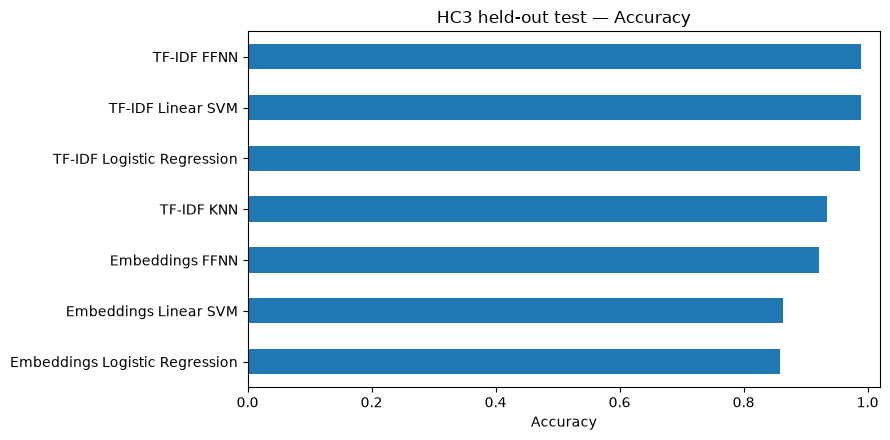

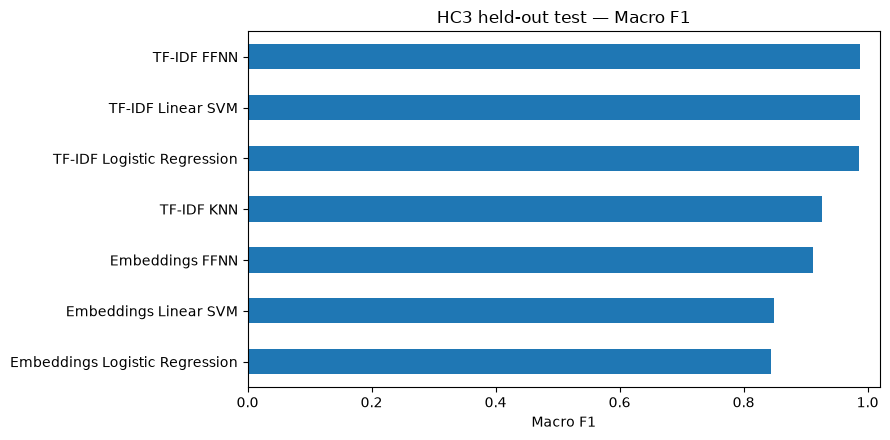

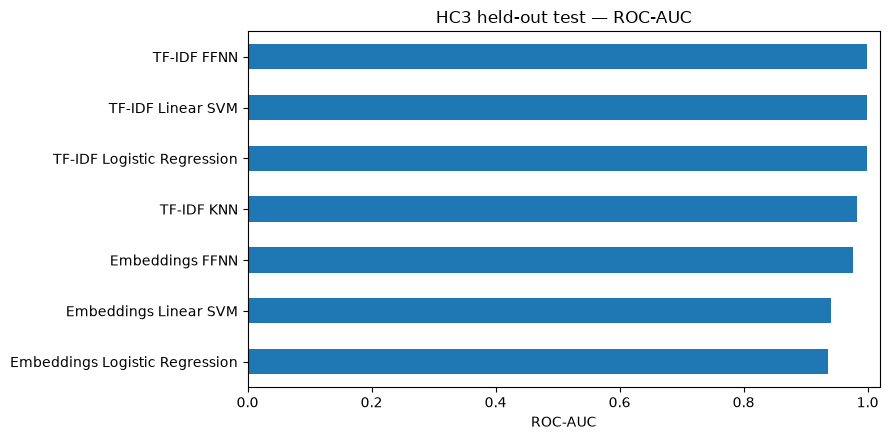

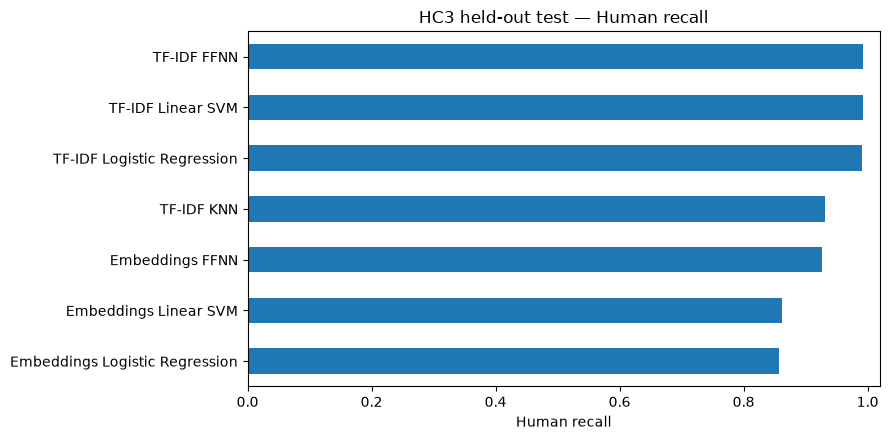

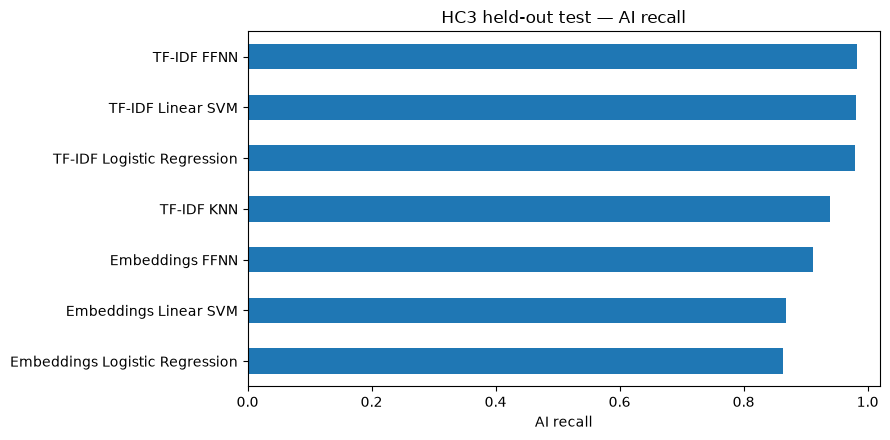

In [9]:
for metric, label in [("accuracy", "Accuracy"), ("macro_f1", "Macro F1"), ("roc_auc", "ROC-AUC"),
                      ("human_recall", "Human recall"), ("ai_recall", "AI recall")]:
    ax = results.sort_values(metric).plot.barh(x="model", y=metric, legend=False, figsize=(9, 4.5))
    ax.set(xlabel=label, ylabel="", title=f"HC3 held-out test — {label}", xlim=(0, 1.02))
    plt.tight_layout()
    plt.show()

## 9. ROC curves, confusion matrices

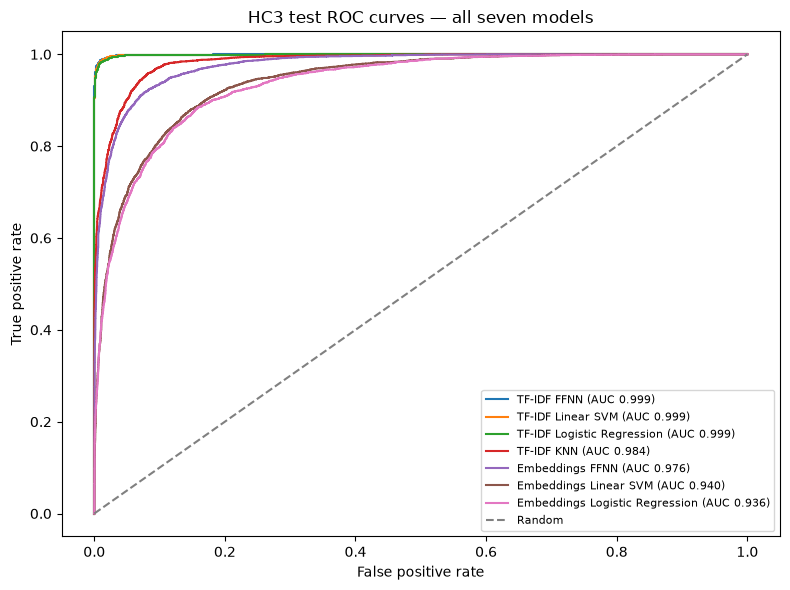

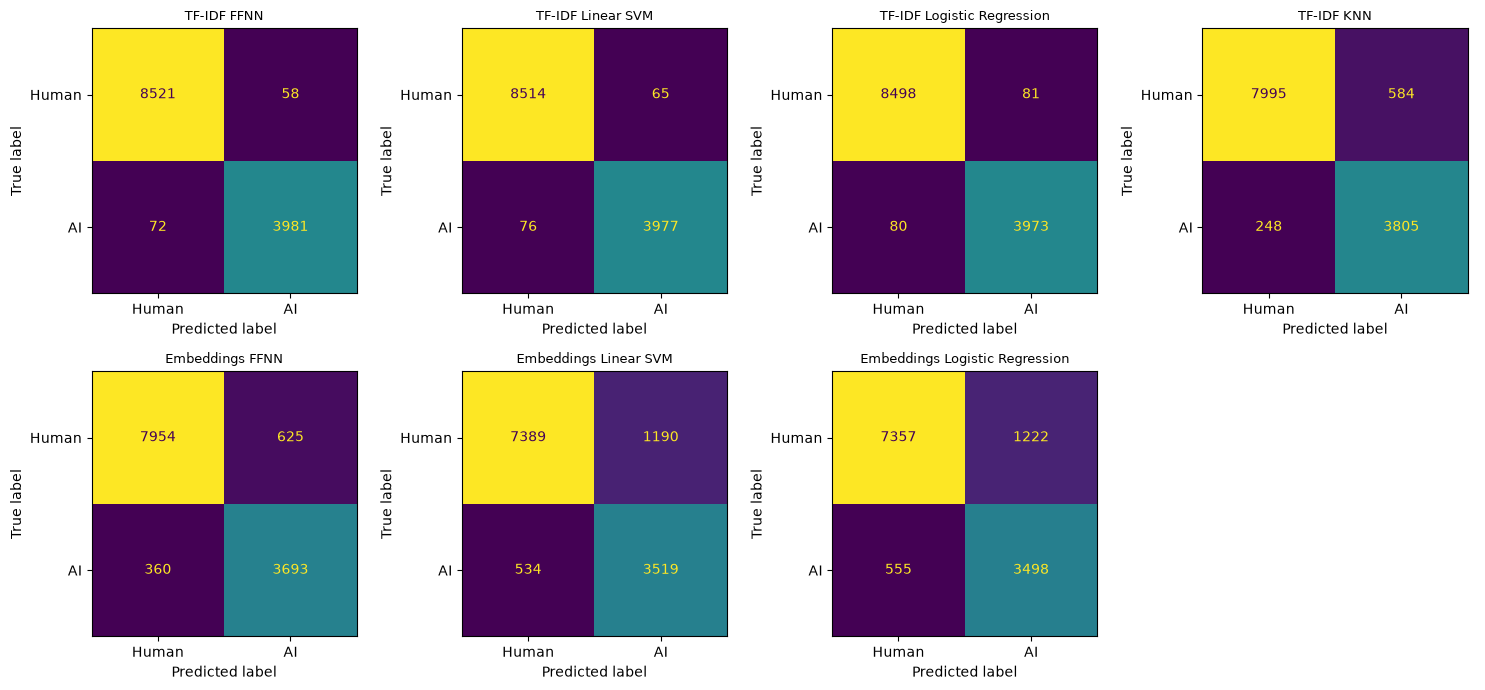

In [10]:
plt.figure(figsize=(8, 6))
for _, rec in results.iterrows():
    fpr, tpr = roc_data[rec["model"]]
    plt.plot(fpr, tpr, label=f"{rec['model']} (AUC {rec['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("HC3 test ROC curves — all seven models")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (_, rec) in zip(axes.flat, results.iterrows()):
    cm = np.array([[rec['tn'], rec['fp']], [rec['fn'], rec['tp']]])
    ConfusionMatrixDisplay(cm, display_labels=["Human", "AI"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(rec['model'], fontsize=9)
for ax in axes.flat[len(results):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 10. Export results to share with the team

These small CSVs can be committed without uploading your model weights or original embedding arrays.

In [14]:
metric_path = RESULTS_DIR / "hc3_model_metrics.csv"

results.to_csv(metric_path, index=False)

print("Saved:", metric_path)

Saved: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation/hc3_model_metrics.csv
